In [55]:
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = ['Arial', 'Noto Sans JP']
plt.rcParams['axes.unicode_minus'] = False

In [28]:
from pathlib import Path

import pandas as pd

# 読み込みたいCSVのファイル名に変更
csv_filename = "LIama.csv"

# リポジトリのルート、develop、develop/scripts のいずれからも実行可能
cwd = Path.cwd().resolve()
testdata_dir = next(
    directory
    for parent in (cwd, *cwd.parents)
    for directory in (parent / "testdata", parent / "develop" / "testdata")
    if directory.is_dir()
)

df = pd.read_csv(
    testdata_dir / csv_filename,
    encoding="utf-8-sig",
    parse_dates=["datetime_jst"],
)

df.head()

,id,epoch_second,problem_id,contest_id,user_id,language,point,length,result,execution_time,datetime_jst,problem_name,difficulty,problem_url
0,58631268,1728611787,APG4b_a,APG4b,LIama,C++ 20 (gcc 12.2),100.0,103,AC,1.0,2024-10-11 10:56:27,1.00.はじめに,NaN,https://atcoder.jp/contests/APG4b/tasks/APG4b_a
1,58631401,1728612226,APG4b_cv,APG4b,LIama,C++ 20 (gcc 12.2),100.0,132,AC,1.0,2024-10-11 11:03:46,1.01,NaN,https://atcoder.jp/contests/APG4b/tasks/APG4b_cv
2,58631486,1728612491,APG4b_cu,APG4b,LIama,C++ 20 (gcc 12.2),0.0,144,CE,NaN,2024-10-11 11:08:11,1.02,NaN,https://atcoder.jp/contests/APG4b/tasks/APG4b_cu
3,58631512,1728612606,APG4b_cu,APG4b,LIama,C++ 20 (gcc 12.2),0.0,144,CE,NaN,2024-10-11 11:10:06,1.02,NaN,https://atcoder.jp/contests/APG4b/tasks/APG4b_cu
4,58631574,1728612785,APG4b_cu,APG4b,LIama,C++ 20 (gcc 12.2),0.0,142,WA,1.0,2024-10-11 11:13:05,1.02,NaN,https://atcoder.jp/contests/APG4b/tasks/APG4b_cu


## 前処理

In [40]:
import io
import math
from datetime import datetime, timedelta, timezone

from IPython.display import Image, display
from matplotlib.figure import Figure
from matplotlib.ticker import MaxNLocator

# 日付の集計は日本時間に統一
JST = timezone(timedelta(hours=9))
# Difficultyが400増えるごとに、灰・茶・緑・水・青・黄・橙・赤に分類
COLORS = [
        '#747781', '#93603A', '#378F58', '#32ABC7',
        '#2B4BB5', '#D7BE40', '#DB923B', '#E84640',
    ]


# 未補正のDifficultyを、AtCoder Problemsの表示用の値に変換
def get_display_difficulty(raw_diff):
    if raw_diff is None or not isinstance(raw_diff, (int, float)) or not math.isfinite(raw_diff):
        return None
    # 400以上はそのまま、400未満は指数関数で補正
    if raw_diff >= 400:
        return int(raw_diff)
    # 非常に小さい値でもオーバーフローしない式を使用
    return int(400 * math.exp(raw_diff / 400 - 1))


# 0〜7が色の区分、8がDifficulty不明の区分
def band(diff):
    return min(7, max(0, diff // 400)) if diff is not None else 8


# Difficultyに対応する描画色を返す
def get_atcoder_color(diff):
    return COLORS[band(diff)] if diff is not None else '#484B55'


# 問題IDから未補正値を取得して、表示用の補正を適用
def difficulty(pid, models):
    model = models.get(pid, {})
    raw = model.get('difficulty')
    if raw is None:
        raw = model.get('experimental_difficulty')
    return get_display_difficulty(raw)


# 全グラフで共有するサイズ・文字・グリッドの設定
def figure(title, *, rectangle=(0.10, 0.22, 0.86, 0.66)):
    fig = Figure(figsize=(10, 5), dpi=130)
    ax = fig.add_axes(rectangle)
    # タイトル・軸ラベル・目盛りの文字サイズ
    ax.set_title(title, fontsize=19)
    ax.set_ylabel('AC count', fontsize=15)
    ax.tick_params(labelsize=13)

    # グリッドは棒や線の背面に表示
    ax.set_axisbelow(True)
    ax.grid(axis='y', alpha=.25)

    # グラフの外枠を表示
    for spine in ax.spines.values():
        spine.set_visible(True)
    return fig, ax


# FigureをPNGへ変換してノートブック上で表示できるようにする
def png(fig):
    output = io.BytesIO()
    fig.savefig(output, format='png', dpi=130)
    output.seek(0)
    return output


# 累積値を保ったまま、減少や行き過ぎのない滑らかな曲線へ補間
def smooth_cumulative(values, points_per_day=16):
    import numpy as np

    y = np.asarray(values, dtype=float)
    original_x = np.arange(len(y), dtype=float) - 1
    if len(y) < 2:
        return original_x, y

    # 各日の増加量。増加量が0の前後は接線の傾きも0にする
    increases = np.diff(y)
    slopes = np.zeros_like(y)
    slopes[0], slopes[-1] = increases[0], increases[-1]
    rising = (increases[:-1] > 0) & (increases[1:] > 0)
    interior = slopes[1:-1]
    interior[rising] = (
        2 * increases[:-1][rising] * increases[1:][rising]
        / (increases[:-1][rising] + increases[1:][rising])
    )

    # 単調な3次Hermite補間：各日の実測値を通り、境界でも傾きがつながる
    t = np.linspace(0, 1, points_per_day, endpoint=False)
    smooth_y = (
        (2 * t**3 - 3 * t**2 + 1) * y[:-1, None]
        + (t**3 - 2 * t**2 + t) * slopes[:-1, None]
        + (-2 * t**3 + 3 * t**2) * y[1:, None]
        + (t**3 - t**2) * slopes[1:, None]
    )
    smooth_x = original_x[:-1, None] + t

    # 最終日の実測値も含める
    return (
        np.append(smooth_x.ravel(), original_x[-1]),
        np.append(smooth_y.ravel(), y[-1]),
    )


### カラーパレットを比較

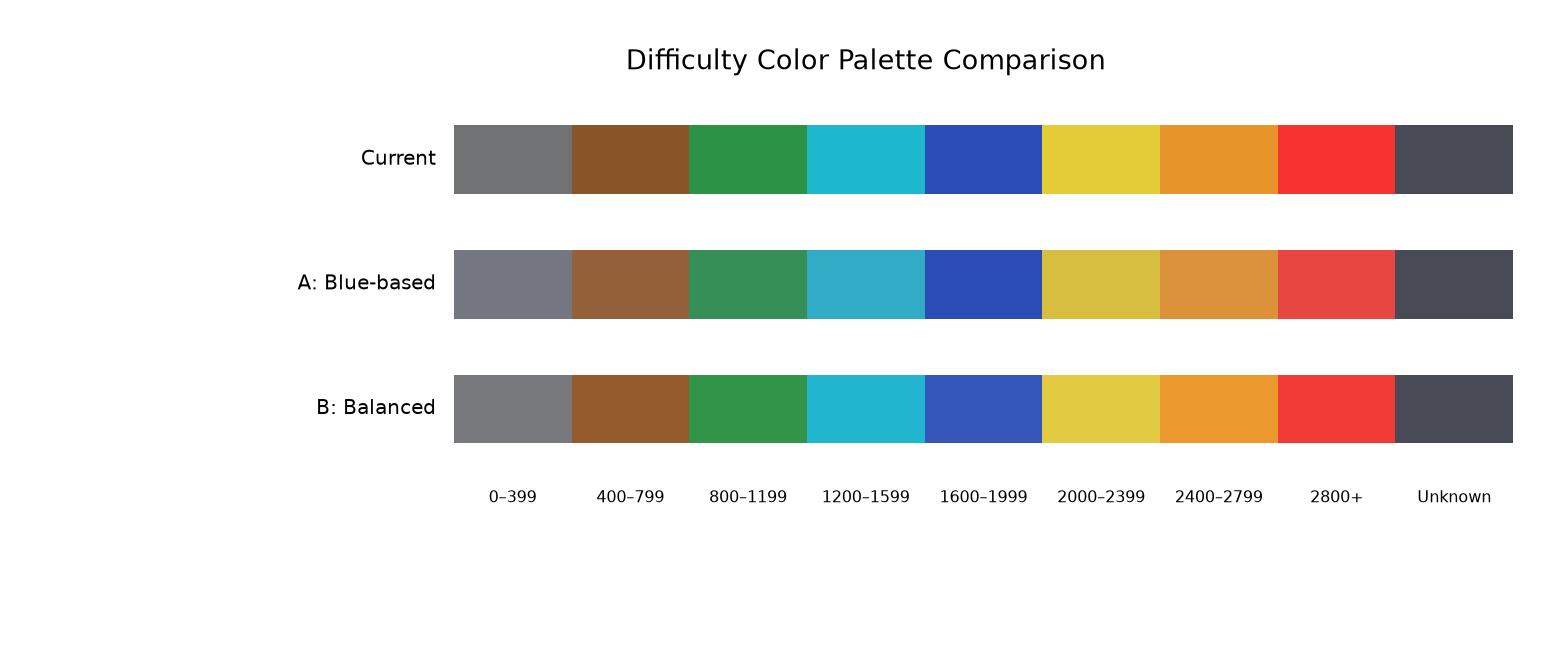

In [39]:
COLOR_PALETTES = {
    'Current': ['#707274', '#895426', '#2C9246', '#1DB8CE', '#2B4BB5', '#E4CC38', '#E7952A', '#F7312E'],
    'A: Blue-based': ['#747781', '#93603A', '#378F58', '#32ABC7', '#2B4BB5', '#D7BE40', '#DB923B', '#E84640'],
    'B: Balanced': ['#77797D', '#945A2C', '#329449', '#21B5D0', '#3455BA', '#E3CA43', '#EB982E', '#F23B36'],
}
UNKNOWN_COLOR = '#484B55'
sample_labels = ['0–399', '400–799', '800–1199', '1200–1599', '1600–1999', '2000–2399', '2400–2799', '2800+', 'Unknown']

color_sample_fig = Figure(figsize=(12, 5), dpi=130)
ax = color_sample_fig.add_axes((0.14, 0.16, 0.83, 0.70))
for row, (name, colors) in enumerate(COLOR_PALETTES.items()):
    y = 2 - row
    for i, color in enumerate(colors + [UNKNOWN_COLOR]):
        ax.barh(y, 1, left=i, height=0.55, color=color, edgecolor='none')
    ax.text(-0.15, y, name, ha='right', va='center', fontsize=11)
for i, label in enumerate(sample_labels):
    ax.text(i + 0.5, -0.65, label, ha='center', va='top', fontsize=9)
ax.set(xlim=(-2, 9), ylim=(-1.1, 2.55))
ax.set_title('Difficulty Color Palette Comparison', fontsize=15, pad=12)
ax.axis('off')
display(Image(data=png(color_sample_fig).getvalue()))

### 前処理：AHCを除いた問題ごとの初ACとDifficulty


In [30]:
# 本体と同じく、ACのみ・AHC除外・各問題の最初のACを採用
first_ac_df = (
    df.loc[
        df["result"].eq("AC")
        & ~df["contest_id"].str.lower().str.startswith("ahc", na=False)
    ]
    .sort_values(["epoch_second", "id"])
    .drop_duplicates("problem_id", keep="first")
)
rows = first_ac_df.to_dict("records")

# CSVのDifficultyは未補正値。本体の関数で表示用の補正を行う
models = {
    row.problem_id: {"difficulty": float(row.difficulty)}
    for row in df.loc[df["difficulty"].notna(), ["problem_id", "difficulty"]]
    .drop_duplicates("problem_id")
    .itertuples(index=False)
}
# グラフのタイトルに表示するユーザー名
user = str(df["user_id"].iloc[0]) if not df.empty else Path(csv_filename).stem
print(f"{user}: 初AC {len(rows)}問（AHC除外）")


LIama: 初AC 675問（AHC除外）


### 集計処理・期間と集計単位の設定


In [13]:
def aggregate(rows, models, period='weekly', aggregation='monthly', now=None):
    if period not in ('weekly', 'monthly', 'all') or aggregation not in ('daily', 'weekly', 'monthly'):
        raise ValueError('期間または集計単位が不正です。')

    # 基準日時より未来の提出は除外し、日本時間の日付へ変換
    now = now or datetime.now(JST)
    today = now.astimezone(JST).date()
    dated = [(datetime.fromtimestamp(r['epoch_second'], JST).date(), r) for r in rows
             if r['epoch_second'] <= now.timestamp()]

    # 期間に応じて横軸の日付と、提出を振り分ける単位を決める
    if period == 'all':
        selected_start = min((d for d, _ in dated), default=today)
        start = selected_start
        # 全期間の場合は、日・週・月の集計単位を選べる
        if aggregation == 'weekly':
            # 週の開始を月曜日にそろえる
            start -= timedelta(days=start.weekday())
            end = today - timedelta(days=today.weekday())
            labels = list(pd.date_range(start, end, freq='7D').date)
            bucket = lambda d: d - timedelta(days=d.weekday())
            title = 'Weekly Effort'
        elif aggregation == 'monthly':
            # 月の開始を1日にそろえる
            start = start.replace(day=1)
            labels = list(pd.date_range(start, today.replace(day=1), freq='MS').date)
            bucket = lambda d: d.replace(day=1)
            title = 'Monthly Effort'
        else:
            labels = list(pd.date_range(start, today, freq='D').date)
            bucket = lambda d: d
            title = 'Daily Effort'
    else:
        # 直近7日・30日は、当日を含めて日単位で集計
        start = today - timedelta(days=6 if period == 'weekly' else 29)
        selected_start = start
        labels = list(pd.date_range(start, today, freq='D').date)
        bucket = lambda d: d
        title = 'Daily Effort'

    # 各期間のAC数を8色＋Difficulty不明の9区分に分ける
    values = [[0] * 9 for _ in labels]
    indices = {d: i for i, d in enumerate(labels)}

    # 累積AC数は、棒グラフの集計単位に関係なく日単位で保持
    total_labels = list(pd.date_range(selected_start, today, freq='D').date)
    daily_counts = [0] * len(total_labels)

    # 初ACを、該当する期間・Difficulty区分へ加算
    for day, row in dated:
        if selected_start <= day <= today:
            values[indices[bucket(day)]][band(difficulty(row['problem_id'], models))] += 1
            daily_counts[(day - selected_start).days] += 1

    # 期間ごとの合計と、日単位の累積AC数を作成
    counts = [sum(v) for v in values]
    cumulative, total = [0], 0
    for count in daily_counts:
        total += count
        cumulative.append(total)

    return {
        'labels': labels,
        'values': values,
        'counts': counts,
        'total_labels': total_labels,
        'daily_counts': daily_counts,
        'cumulative': cumulative,
        'total': total,
        'title': title,
    }


# Difficulty不明の問題を除き、ヒストグラム用の値を取り出す
def histogram_values(rows, models):
    return [v for row in rows if (v := difficulty(row['problem_id'], models)) is not None]


# 描画する期間と集計単位をここで変更
# period: "weekly"（直近7日）, "monthly"（直近30日）, "all"（全期間）
# aggregation: "daily", "weekly", "monthly"（period="all" のとき有効）
period = "all"
aggregation = "daily"

data = aggregate(rows, models, period=period, aggregation=aggregation)


## 描画コード

### AC数：Difficultyの色別の積み上げ棒グラフ


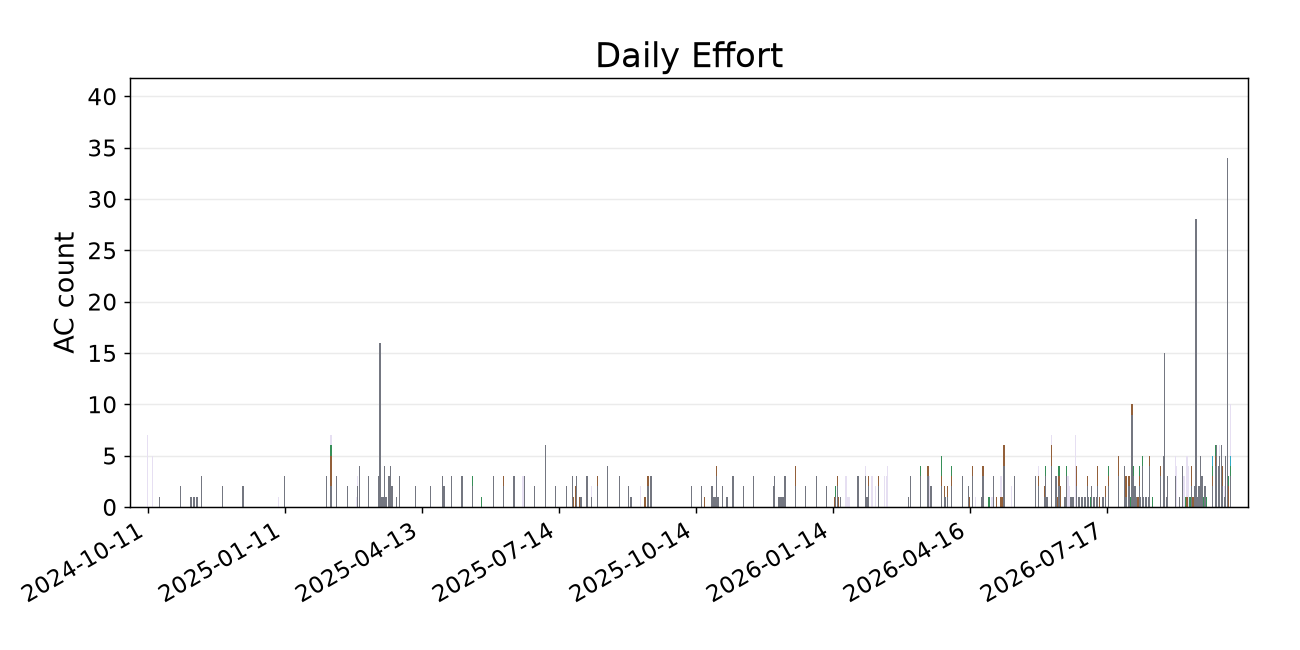

In [41]:
# Figureを作成し、AC数の目盛りを整数にする
effort_fig, ax = figure(data['title'])
ax.yaxis.set_major_locator(MaxNLocator(integer=True, min_n_ticks=2))

# Difficultyの区分ごとに棒を積み上げる（最後の色はDifficulty不明）
x = list(range(len(data['labels'])))
bottom = [0] * len(x)
for i, col in enumerate(COLORS + ['#e6dff2']):
    heights = [row[i] for row in data['values']]
    ax.bar(x, heights, bottom=bottom, color=col, edgecolor='none', linewidth=0)
    bottom = [b + h for b, h in zip(bottom, heights)]

# 棒が多いと文字が重なるため、16本以下の場合だけAC数を表示
if len(x) <= 16:
    for index, count in zip(x, data['counts']):
        ax.text(index, count + .04, str(count), ha='center', va='bottom', fontsize=13)

# AC数のラベルが上端に重ならないよう、縦軸に余白を確保
ax.set_ylim(0, max(1, max(bottom, default=0)) * 1.22 + .3)

# 日付ラベルを約8個に間引き、斜めに表示
stride = max(1, (len(x) + 7) // 8)
positions = x[::stride]
ax.set_xticks(
    positions,
    [data['labels'][i].isoformat() for i in positions],
    rotation=30,
    ha='right',
)

# 最初と最後の棒・線が外枠に重ならないよう、横軸に余白を確保
padding = len(x) * .015
ax.set_xlim(-1 - max(.4, padding), len(x) - 1 + max(.6, padding))

# グラフをノートブック内に表示
display(Image(data=png(effort_fig).getvalue()))


### 累積AC数：Total Effort


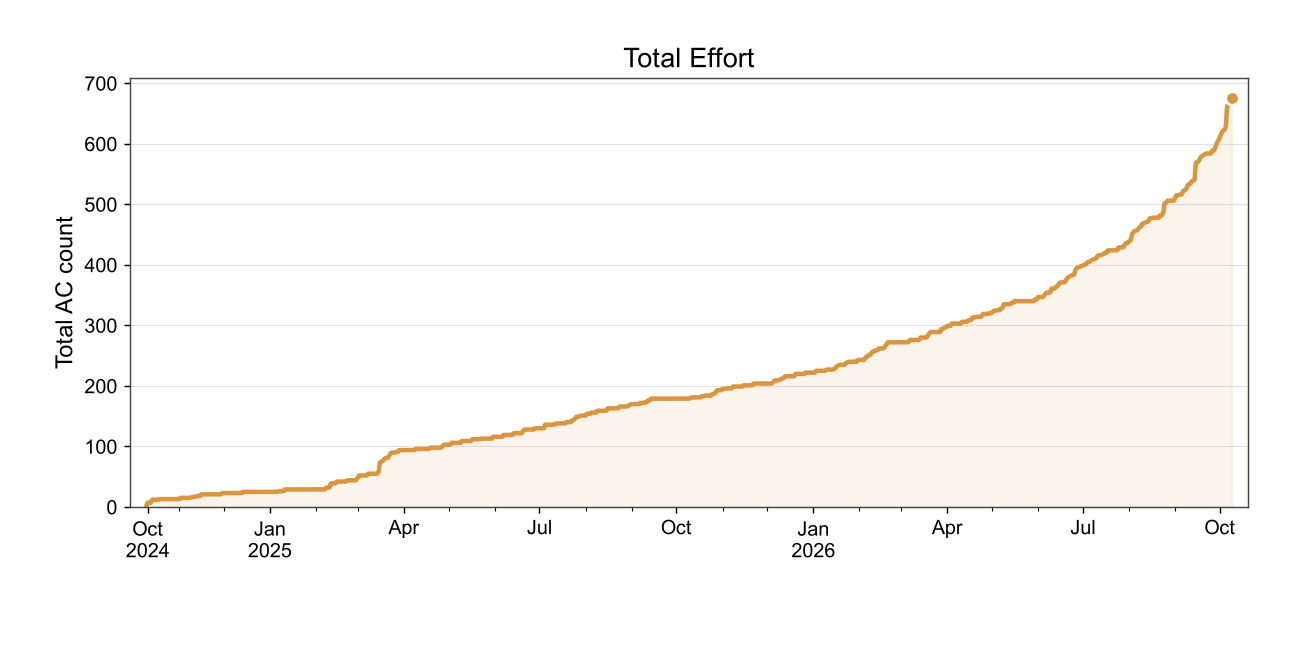

In [128]:
from datetime import date
from matplotlib.ticker import FixedLocator, MultipleLocator
from scipy.interpolate import PchipInterpolator
import numpy as np

# 累積AC数
total_effort_fig, ax = figure('Total Effort')
dates = [d if isinstance(d, date) else date.fromisoformat(str(d)) for d in data['total_labels']]
x = np.arange(len(dates))
y = np.asarray(data['cumulative'])
line_color = '#DB953F'

# PCHIP補間で滑らかな曲線を生成
x_data = np.arange(-1, len(dates))
if len(x_data) >= 2:
    interpolator = PchipInterpolator(x_data, y)
    x_smooth = np.linspace(x_data[0], x_data[-1], max(500, len(x_data) * 4))
    y_smooth = interpolator(x_smooth)
else:
    x_smooth, y_smooth = x_data, y

# 曲線・塗りつぶし・終点マーカー
ax.fill_between(x_smooth, y_smooth, 0, color=line_color, alpha=0.10, zorder=1)
ax.plot(x_smooth, y_smooth, color=line_color, linewidth=2.5, zorder=3)
if len(x):
    ax.scatter(x[-1], y[-1], s=55, color=line_color,
               edgecolor='white', linewidth=1.5, zorder=4)

# 表示期間に応じて日付目盛りを調整
if dates:
    days = (dates[-1] - dates[0]).days
    if days <= 31: major_months, minor_months, day_step = 0, 0, 3
    elif days <= 92: major_months, minor_months, day_step = 0, 0, 7
    elif days <= 183: major_months, minor_months, day_step = 0, 0, 14
    elif days <= 366: major_months, minor_months, day_step = 1, 0, 0
    elif days <= 1096: major_months, minor_months, day_step = 3, 1, 0
    elif days <= 2192: major_months, minor_months, day_step = 6, 3, 0
    else: major_months, minor_months, day_step = 12, 3, 0

    if day_step:
        major = [i for i, d in enumerate(dates)
                 if (d - dates[0]).days % day_step == 0]
        minor = [i for i, d in enumerate(dates)
                 if (d - dates[0]).days % max(1, day_step // 2) == 0]
    else:
        major = [i for i, d in enumerate(dates)
                 if d.day == 1 and (d.month - 1) % major_months == 0]
        minor = [i for i, d in enumerate(dates)
                 if d.day == 1 and (d.month - 1) % (minor_months or major_months) == 0]
        major = sorted(set([0] + major))

    # 開始日に近い目盛りの重複を避ける
    min_gap = max(1, int(len(dates) * 0.045))
    major = [i for i in major if i == 0 or i >= min_gap]

    # 月名で表示し、年が変わる最初の目盛りだけ年を併記
    labels = []
    previous_year = None
    for i in major:
        d = dates[i]
        label = f'{d.strftime("%b")} {d.day}' if day_step else d.strftime('%b')
        labels.append(f'{label}\n{d.year}' if d.year != previous_year else label)
        previous_year = d.year

    ax.xaxis.set_major_locator(FixedLocator(major))
    ax.set_xticklabels(labels)
    ax.xaxis.set_minor_locator(FixedLocator([i for i in minor if i not in major]))

# 軸・ラベル・グリッド・外枠
padding = len(x) * 0.015
ax.set_xlim(-1 - max(0.4, padding), len(x) - 1 + max(0.6, padding))
ax.set_ylim(bottom=0)
ax.set_ylabel('Total AC count', fontsize=13)
ax.title.set_fontsize(15)

# 累積AC数に応じて縦軸の目盛り間隔を自動調整
max_ac = max(y, default=0)
step = 50 if max_ac <= 300 else 100 if max_ac <= 1000 else 200 if max_ac <= 2000 else 500
ax.yaxis.set_major_locator(MultipleLocator(step))
ax.tick_params(axis='both', colors='black', labelsize=11)

# 横方向のグリッドのみ表示
ax.set_axisbelow(True)
ax.yaxis.grid(True, color='#D5D5D5', linewidth=0.6, alpha=0.7)
ax.xaxis.grid(False, which='both')

# 外枠
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color('#454545')
    spine.set_linewidth(0.8)
    spine.set_zorder(10)

display(Image(data=png(total_effort_fig).getvalue()))


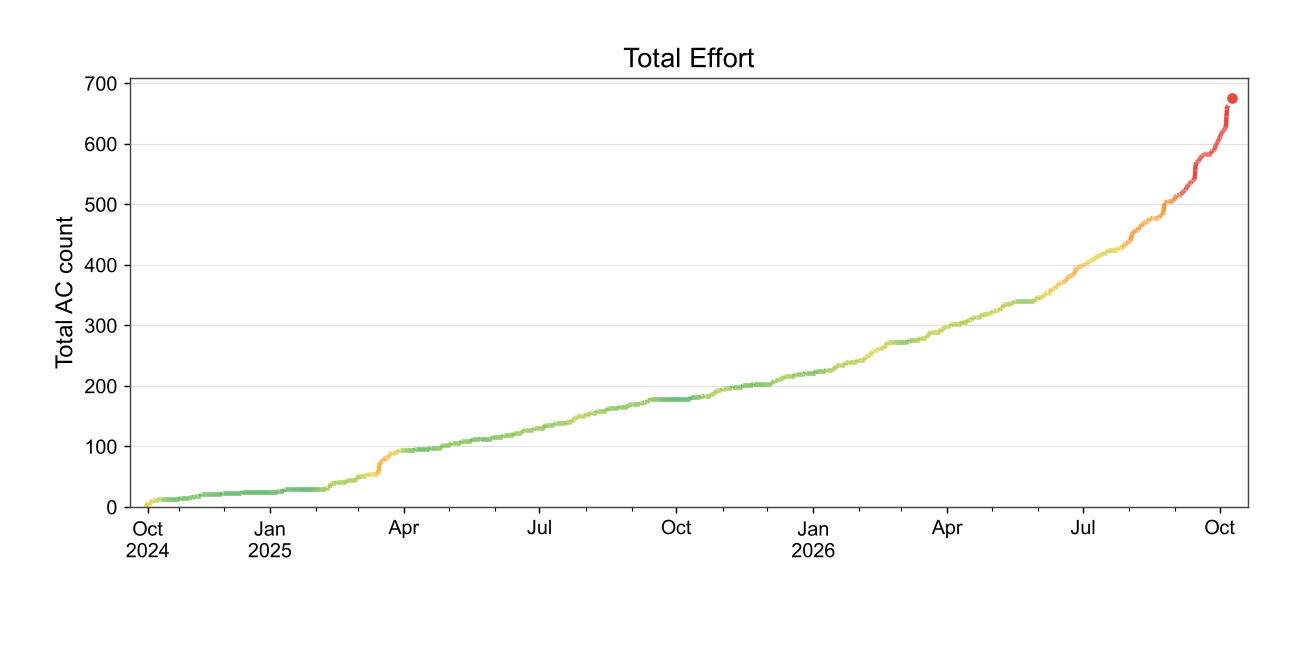

In [131]:

from datetime import date
import numpy as np
from scipy.interpolate import PchipInterpolator
from scipy.ndimage import gaussian_filter1d
from matplotlib.ticker import FixedLocator, MultipleLocator
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap, Normalize

# ============================================================
# Total Effort — 精進速度による色分け
# ============================================================

total_effort_fig, ax = figure('Total Effort')

dates = [d if isinstance(d, date) else date.fromisoformat(str(d)) for d in data['total_labels']]
x = np.arange(len(dates))
y = np.asarray(data['cumulative'], dtype=float)
x_data = np.arange(-1, len(dates))

# 色の設定：緑（低速）→ 黄 → 橙 → 赤（高速）
speed_cmap = LinearSegmentedColormap.from_list(
    'effort_speed',
    ['#32A852', '#A8CB42', '#F3D34A', '#F29A38', '#E64B42']
)

# 精進速度：日ごとのAC数をガウス平滑化
daily_ac = np.diff(y)
speed = gaussian_filter1d(daily_ac, sigma=7) if len(daily_ac) > 1 else daily_ac
speed_norm = Normalize(vmin=0, vmax=3.0)

# PCHIP補間で累積AC数の曲線を滑らかにする
if len(x_data) >= 2:
    x_smooth = np.linspace(x_data[0], x_data[-1], max(500, len(x_data) * 4))
    y_smooth = PchipInterpolator(x_data, y)(x_smooth)

    # 補間曲線上の精進速度
    speed_smooth = np.interp(x_smooth, x, speed, left=speed[0], right=speed[-1])

    # 曲線を線分に分割して着色
    points = np.column_stack([x_smooth, y_smooth])
    segments = np.stack([points[:-1], points[1:]], axis=1)

    lc = LineCollection(
        segments, cmap=speed_cmap, norm=speed_norm,
        linewidth=2.5, zorder=3
    )
    lc.set_array((speed_smooth[:-1] + speed_smooth[1:]) / 2)
    ax.add_collection(lc)

    # 曲線下の薄い塗りつぶし
    # ax.fill_between(x_smooth, y_smooth, 0,
    #                 color='#DB953F', alpha=0.10, zorder=1)

    # 終点マーカー
    if len(x):
        ax.scatter(x[-1], y[-1], s=55,
                   color=speed_cmap(speed_norm(speed[-1])),
                   edgecolor='white', linewidth=1.5, zorder=4)

# ============================================================
# 日付目盛り
# ============================================================

if dates:
    days = (dates[-1] - dates[0]).days

    if days <= 31: major_months, minor_months, day_step = 0, 0, 3
    elif days <= 92: major_months, minor_months, day_step = 0, 0, 7
    elif days <= 183: major_months, minor_months, day_step = 0, 0, 14
    elif days <= 366: major_months, minor_months, day_step = 1, 0, 0
    elif days <= 1096: major_months, minor_months, day_step = 3, 1, 0
    elif days <= 2192: major_months, minor_months, day_step = 6, 3, 0
    else: major_months, minor_months, day_step = 12, 3, 0

    if day_step:
        major = [i for i, d in enumerate(dates)
                 if (d - dates[0]).days % day_step == 0]
        minor = [i for i, d in enumerate(dates)
                 if (d - dates[0]).days % max(1, day_step // 2) == 0]
    else:
        major = [i for i, d in enumerate(dates)
                 if d.day == 1 and (d.month - 1) % major_months == 0]
        minor = [i for i, d in enumerate(dates)
                 if d.day == 1 and (d.month - 1) % (minor_months or major_months) == 0]
        major = sorted(set([0] + major))

    # 開始日と近すぎる目盛りを除外
    min_gap = max(1, int(len(dates) * 0.045))
    major = [i for i in major if i == 0 or i >= min_gap]

    # 月名と年を表示
    labels = []
    previous_year = None
    for i in major:
        d = dates[i]
        label = f'{d.strftime("%b")} {d.day}' if day_step else d.strftime('%b')
        labels.append(f'{label}\n{d.year}' if d.year != previous_year else label)
        previous_year = d.year

    ax.xaxis.set_major_locator(FixedLocator(major))
    ax.set_xticklabels(labels)
    ax.xaxis.set_minor_locator(FixedLocator([i for i in minor if i not in major]))

# ============================================================
# 軸・グリッド・外枠
# ============================================================

padding = len(x) * 0.015
ax.set_xlim(-1 - max(0.4, padding), len(x) - 1 + max(0.6, padding))
ax.set_ylim(bottom=0)
ax.set_ylabel('Total AC count', fontsize=13)
ax.title.set_fontsize(15)

max_ac = max(y, default=0)
step = 50 if max_ac <= 300 else 100 if max_ac <= 1000 else 200 if max_ac <= 2000 else 500
ax.yaxis.set_major_locator(MultipleLocator(step))
ax.tick_params(axis='both', colors='black', labelsize=11)

# 横方向のグリッドのみ
ax.set_axisbelow(True)
ax.yaxis.grid(True, color='#D5D5D5', linewidth=0.6, alpha=0.7)
ax.xaxis.grid(False, which='both')

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color('#454545')
    spine.set_linewidth(0.8)
    spine.set_zorder(10)

display(Image(data=png(total_effort_fig).getvalue()))



In [132]:
print("models sample:", list(models.items())[:2])
print("rows sample:", rows[:2])

models sample: [('abc376_a', {'difficulty': -823.0}), ('abc378_a', {'difficulty': -755.0})]
rows sample: [{'id': 58631268, 'epoch_second': 1728611787, 'problem_id': 'APG4b_a', 'contest_id': 'APG4b', 'user_id': 'LIama', 'language': 'C++ 20 (gcc 12.2)', 'point': 100.0, 'length': 103, 'result': 'AC', 'execution_time': 1.0, 'datetime_jst': Timestamp('2024-10-11 10:56:27'), 'problem_name': '1.00.はじめに', 'difficulty': nan, 'problem_url': 'https://atcoder.jp/contests/APG4b/tasks/APG4b_a'}, {'id': 58631401, 'epoch_second': 1728612226, 'problem_id': 'APG4b_cv', 'contest_id': 'APG4b', 'user_id': 'LIama', 'language': 'C++ 20 (gcc 12.2)', 'point': 100.0, 'length': 132, 'result': 'AC', 'execution_time': 1.0, 'datetime_jst': Timestamp('2024-10-11 11:03:46'), 'problem_name': '1.01', 'difficulty': nan, 'problem_url': 'https://atcoder.jp/contests/APG4b/tasks/APG4b_cv'}]


### TEEで色付け

In [ ]:
import requests, json, time
import numpy as np
from pathlib import Path
from datetime import datetime, timedelta, timezone
from collections import defaultdict

BASE = 'https://kenkoooo.com/atcoder'
CACHE = Path('tee_cache')
CACHE.mkdir(exist_ok=True)
JST = timezone(timedelta(hours=9))
session = requests.Session()

def get_json(url):
    response = session.get(url, timeout=60)
    response.raise_for_status()
    return response.json()

# 問題モデルの取得（キャッシュがあれば再利用）
model_path = CACHE / 'problem-models.json'
if model_path.exists():
    tee_models = json.loads(model_path.read_text())
else:
    tee_models = get_json(f'{BASE}/resources/problem-models.json')
    model_path.write_text(json.dumps(tee_models))
    time.sleep(1.2)

# 提出履歴を全件取得（APIは1回最大500件）
submission_path = CACHE / f'{user}_submissions.json'
if submission_path.exists():
    tee_rows = json.loads(submission_path.read_text())
else:
    tee_rows = []
    from_second = 0
    while True:
        batch = get_json(
            f'{BASE}/atcoder-api/v3/user/submissions'
            f'?user={user}&from_second={from_second}'
        )
        if not batch:
            break
        tee_rows.extend(batch)
        print(f'\rDownloaded: {len(tee_rows)} submissions', end='')
        if len(batch) < 500:
            break
        next_second = max(r['epoch_second'] for r in batch) + 1
        if next_second <= from_second:
            raise RuntimeError('Submission pagination did not advance')
        from_second = next_second
        time.sleep(1.2)
    tee_rows = list({r['id']: r for r in tee_rows}.values())
    submission_path.write_text(json.dumps(tee_rows))
    print()

# 問題ごとのTEEを計算（秒）
tee_by_problem = {}
for problem_id, model in tee_models.items():
    slope, intercept = model.get('slope'), model.get('intercept')
    if slope is not None and intercept is not None:
        tee_by_problem[problem_id] = float(np.exp(4000 * slope + intercept))

# 初ACだけを抽出して日別TEEを集計
first_ac = {}
for row in sorted(tee_rows, key=lambda r: (r['epoch_second'], r['id'])):
    if row['result'] == 'AC':
        first_ac.setdefault(row['problem_id'], row)

daily_tee = defaultdict(float)
missing = 0

for problem_id, row in first_ac.items():
    if problem_id not in tee_by_problem:
        missing += 1
        continue
    day = datetime.fromtimestamp(row['epoch_second'], JST).date()
    daily_tee[day] += tee_by_problem[problem_id]

print(f'First AC: {len(first_ac)}')
print(f'TEE available: {len(first_ac) - missing}')
print(f'TEE unavailable: {missing}')
print(f'Total TEE: {sum(daily_tee.values()) / 3600:.2f} hours')

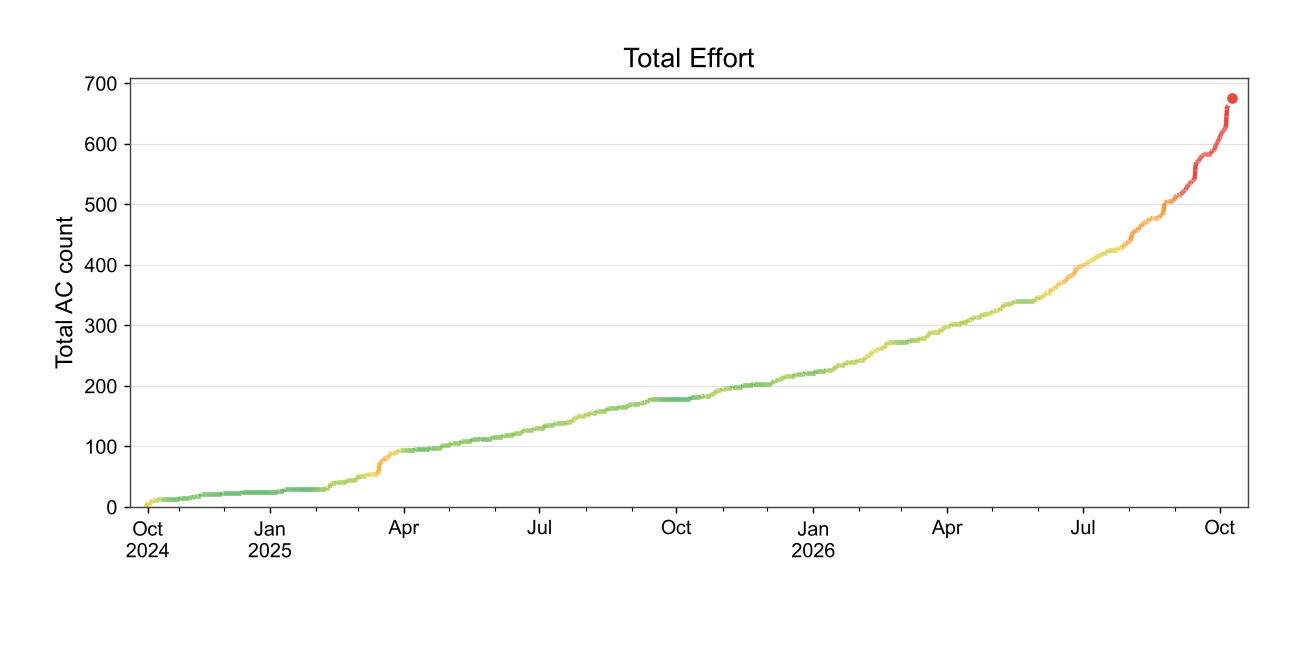

In [134]:

from datetime import date
import numpy as np
from scipy.interpolate import PchipInterpolator
from scipy.ndimage import gaussian_filter1d
from matplotlib.ticker import FixedLocator, MultipleLocator
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap, Normalize

# ============================================================
# Total Effort — 精進速度による色分け
# ============================================================

total_effort_fig, ax = figure('Total Effort')

dates = [d if isinstance(d, date) else date.fromisoformat(str(d)) for d in data['total_labels']]
x = np.arange(len(dates))
y = np.asarray(data['cumulative'], dtype=float)
x_data = np.arange(-1, len(dates))

# 色の設定：緑（低速）→ 黄 → 橙 → 赤（高速）
speed_cmap = LinearSegmentedColormap.from_list(
    'effort_speed',
    ['#32A852', '#A8CB42', '#F3D34A', '#F29A38', '#E64B42']
)

# 精進速度：日ごとのAC数をガウス平滑化
daily_ac = np.diff(y)
speed = gaussian_filter1d(daily_ac, sigma=7) if len(daily_ac) > 1 else daily_ac
speed_norm = Normalize(vmin=0, vmax=3.0)


from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap, Normalize
from scipy.ndimage import gaussian_filter1d

# 精進速度のカラーパレット
speed_cmap = LinearSegmentedColormap.from_list(
    'effort_speed',
    ['#32A852', '#A8CB42', '#F3D34A', '#F29A38', '#E64B42']
)

# 1日あたりのAC数を平滑化（sigma=7日）
daily_ac = np.diff(y)
speed = gaussian_filter1d(daily_ac.astype(float), sigma=7)

# 累積AC数をPCHIP補間
x_data = np.arange(-1, len(dates))
x_smooth = np.linspace(x_data[0], x_data[-1], max(500, len(x_data) * 4))
y_smooth = PchipInterpolator(x_data, y)(x_smooth)

# 補間した曲線上で精進速度を評価
speed_smooth = np.interp(
    x_smooth, np.arange(len(dates)), speed
)

# 曲線を短い線分に分割して、速度に応じて着色
points = np.column_stack([x_smooth, y_smooth])
segments = np.stack([points[:-1], points[1:]], axis=1)

norm = Normalize(vmin=0, vmax=3.0)
lc = LineCollection(segments, cmap=speed_cmap, norm=norm,
                    linewidth=2.5, zorder=3)
lc.set_array((speed_smooth[:-1] + speed_smooth[1:]) / 2)
ax.add_collection(lc)

# 曲線の下を薄く塗りつぶす
# ax.fill_between(x_smooth, y_smooth, 0,
#                 color='#DB953F', alpha=0.10, zorder=1)

# 終点マーカー
ax.scatter(x_smooth[-1], y_smooth[-1], s=55,
           color=speed_cmap(norm(speed_smooth[-1])),
           edgecolor='white', linewidth=1.5, zorder=4)

# ============================================================
# 日付目盛り
# ============================================================

if dates:
    days = (dates[-1] - dates[0]).days

    if days <= 31: major_months, minor_months, day_step = 0, 0, 3
    elif days <= 92: major_months, minor_months, day_step = 0, 0, 7
    elif days <= 183: major_months, minor_months, day_step = 0, 0, 14
    elif days <= 366: major_months, minor_months, day_step = 1, 0, 0
    elif days <= 1096: major_months, minor_months, day_step = 3, 1, 0
    elif days <= 2192: major_months, minor_months, day_step = 6, 3, 0
    else: major_months, minor_months, day_step = 12, 3, 0

    if day_step:
        major = [i for i, d in enumerate(dates)
                 if (d - dates[0]).days % day_step == 0]
        minor = [i for i, d in enumerate(dates)
                 if (d - dates[0]).days % max(1, day_step // 2) == 0]
    else:
        major = [i for i, d in enumerate(dates)
                 if d.day == 1 and (d.month - 1) % major_months == 0]
        minor = [i for i, d in enumerate(dates)
                 if d.day == 1 and (d.month - 1) % (minor_months or major_months) == 0]
        major = sorted(set([0] + major))

    # 開始日と近すぎる目盛りを除外
    min_gap = max(1, int(len(dates) * 0.045))
    major = [i for i in major if i == 0 or i >= min_gap]

    # 月名と年を表示
    labels = []
    previous_year = None
    for i in major:
        d = dates[i]
        label = f'{d.strftime("%b")} {d.day}' if day_step else d.strftime('%b')
        labels.append(f'{label}\n{d.year}' if d.year != previous_year else label)
        previous_year = d.year

    ax.xaxis.set_major_locator(FixedLocator(major))
    ax.set_xticklabels(labels)
    ax.xaxis.set_minor_locator(FixedLocator([i for i in minor if i not in major]))

# ============================================================
# 軸・グリッド・外枠
# ============================================================

padding = len(x) * 0.015
ax.set_xlim(-1 - max(0.4, padding), len(x) - 1 + max(0.6, padding))
ax.set_ylim(bottom=0)
ax.set_ylabel('Total AC count', fontsize=13)
ax.title.set_fontsize(15)

max_ac = max(y, default=0)
step = 50 if max_ac <= 300 else 100 if max_ac <= 1000 else 200 if max_ac <= 2000 else 500
ax.yaxis.set_major_locator(MultipleLocator(step))
ax.tick_params(axis='both', colors='black', labelsize=11)

# 横方向のグリッドのみ
ax.set_axisbelow(True)
ax.yaxis.grid(True, color='#D5D5D5', linewidth=0.6, alpha=0.7)
ax.xaxis.grid(False, which='both')

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color('#454545')
    spine.set_linewidth(0.8)
    spine.set_zorder(10)

display(Image(data=png(total_effort_fig).getvalue()))

In [136]:
from pathlib import Path

print("TEE cache:", list(Path("tee_cache").glob("*")))
print("tee_models:", "tee_models" in globals())
print("tee_rows:", "tee_rows" in globals())

TEE cache: []
tee_models: False
tee_rows: False


In [137]:

from datetime import date
import numpy as np
from matplotlib.ticker import MaxNLocator

# 日付・累積AC数・累積TEE
dates = [d if isinstance(d, date) else date.fromisoformat(str(d)) for d in data['total_labels']]
x = np.arange(len(dates))
cumulative_ac = np.asarray(data['cumulative'][1:], dtype=float)
cumulative_tee = np.cumsum([daily_tee.get(d, 0.0) / 3600 for d in dates])

# グラフ作成
compare_fig, ax = figure('Cumulative AC vs TEE')
ax2 = ax.twinx()

# 折れ線（補間・平滑化なし）
ax.plot(x, cumulative_ac, color='#3655AC', linewidth=2, label='AC count')
ax2.plot(x, cumulative_tee, color='#DB953F', linewidth=2, label='TEE')

# 日付ラベル（約3か月ごと）
major = [i for i, d in enumerate(dates) if d.day == 1 and d.month in (1, 4, 7, 10)]
major = sorted(set(([0] if dates else []) + major))

labels = []
previous_year = None
for i in major:
    d = dates[i]
    labels.append(f'{d.strftime("%b")}\n{d.year}' if d.year != previous_year else d.strftime('%b'))
    previous_year = d.year

ax.set_xticks(major, labels)

# 軸・目盛り・グリッド
ax.set_xlim(-max(1, len(x) * 0.015), len(x) - 1 + max(1, len(x) * 0.015))
ax.set_ylim(bottom=0)
ax2.set_ylim(bottom=0)
ax.set_ylabel('Total AC count', fontsize=13, color='#3655AC')
ax2.set_ylabel('Cumulative TEE (hours)', fontsize=13, color='#DB953F')
ax.title.set_fontsize(15)

ax.yaxis.set_major_locator(MaxNLocator(nbins=7, integer=True))
ax2.yaxis.set_major_locator(MaxNLocator(nbins=7))
ax.tick_params(axis='x', labelsize=11)
ax.tick_params(axis='y', labelcolors='#3655AC', labelsize=11)
ax2.tick_params(axis='y', labelcolors='#DB953F', labelsize=11)

ax.set_axisbelow(True)
ax.yaxis.grid(True, color='#D5D5D5', linewidth=0.6, alpha=0.7)
ax.xaxis.grid(False)

for axis in (ax, ax2):
    for spine in axis.spines.values():
        spine.set_color('#454545')
        spine.set_linewidth(0.8)

# 凡例
lines = ax.get_lines() + ax2.get_lines()
ax.legend(lines, [line.get_label() for line in lines],
          loc='upper left', frameon=False, fontsize=11)

display(Image(data=png(compare_fig).getvalue()))


NameError: name 'daily_tee' is not defined

### Difficulty分布：全期間の初AC


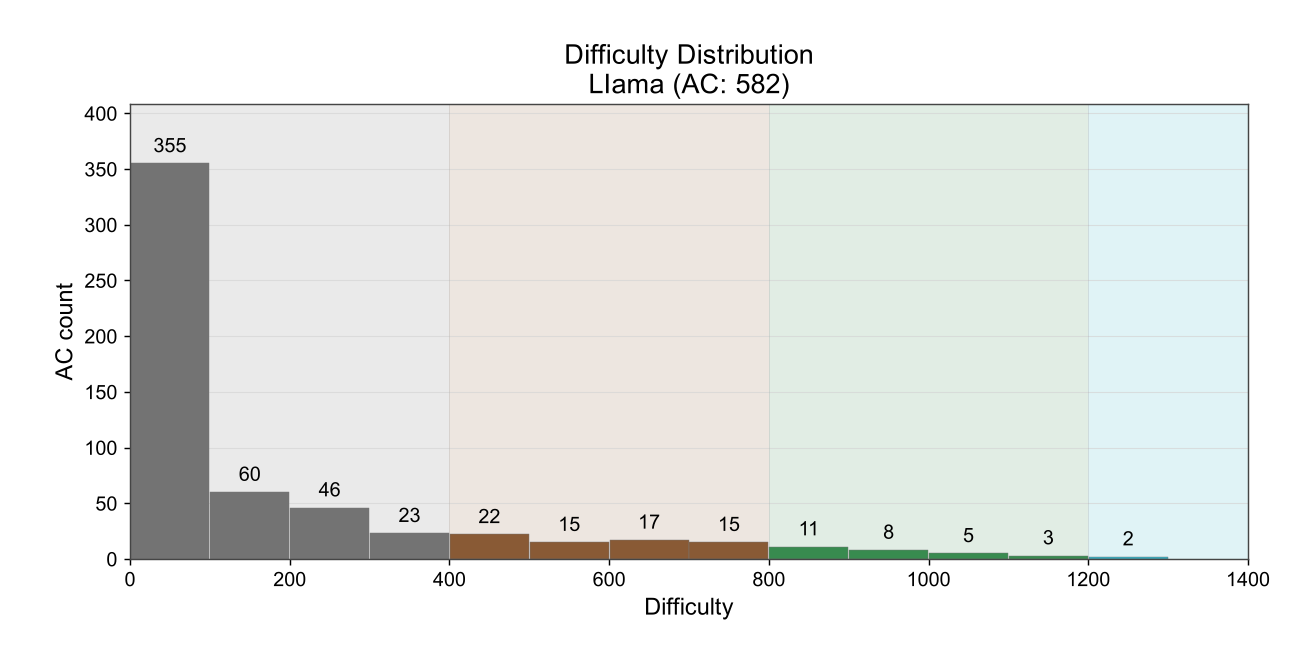

In [124]:
# 全期間のDifficultyを100刻みで集計（不明な問題は除外）
values = histogram_values(rows, models)
upper = max(400, (max(values, default=0) // 100 + 1) * 100)
x_limit = upper + 100
starts = list(range(0, upper, 100))
counts = [0] * len(starts)
for value in values:
    counts[value // 100] += 1

# グラフ作成
difficulty_fig, ax = figure(
    f'Difficulty Distribution\n{user} (AC: {len(values)})',
    rectangle=(0.10, 0.14, 0.86, 0.70),
)
ax.title.set_fontsize(15)

# Difficulty帯の背景（枠線なし）
for i, col in enumerate(COLORS):
    low = i * 400
    high = (i + 1) * 400 if i < 7 else x_limit
    if low < x_limit:
        ax.axvspan(
            low, min(high, x_limit),
            facecolor=col, edgecolor='none',
            alpha=0.15, zorder=0
        )

# 400刻みの境界線
for x in range(400, x_limit, 400):
    ax.axvline(
        x, color='#AAAAAA',
        linewidth=0.3, alpha=0.6, zorder=2
    )

# 棒グラフ
ax.bar(
    [s + 50 for s in starts], counts,
    width=99,
    color=[COLORS[min(s // 400, 7)] for s in starts],
    edgecolor='#777777', linewidth=0.25, zorder=3
)

# 問題数のラベル
for s, count in zip(starts, counts):
    if count:
        ax.annotate(
            str(count), (s + 50, count),
            xytext=(0, 4), textcoords='offset points',
            ha='center', va='bottom',
            fontsize=11, color='black', zorder=4
        )

# 軸・ラベル・グリッド・外枠
ax.set_xlim(0, x_limit)
ax.set_ylim(0, max(1, max(counts, default=0) * 1.15 + 0.15))
ax.set_xlabel('Difficulty', fontsize=13)
ax.set_ylabel('AC count', fontsize=13)
ax.yaxis.set_major_locator(MaxNLocator(integer=True, min_n_ticks=2))

ax.set_axisbelow(True)
ax.yaxis.grid(True, color='#D5D5D5', linewidth=0.6, alpha=0.7)
ax.xaxis.grid(False)
ax.tick_params(axis='both', colors='black', labelsize=11)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color('#454545')
    spine.set_linewidth(0.8)
    spine.set_zorder(10)

display(Image(data=png(difficulty_fig).getvalue()))




## 累積AC数と累積TEEの比較（最終値をAC数に合わせる）

この4セルは既存セルを変更せず追加したものです。CSV前処理と期間集計で作った `rows`・`data`、共通の `figure()`・`png()` を読み取ります。既存のTEE取得セルの実行は必須ではありません。

TEEはAtCoder Problemsの [calculateTopPlayerEquivalentEffort](https://github.com/kenkoooo/AtCoderProblems/blob/main/atcoder-problems-frontend/src/utils/ProblemModelUtil.ts) に従い、時間モデルから `exp(4000 * slope + intercept)` 秒を計算します。[時間モデル判定](https://github.com/kenkoooo/AtCoderProblems/blob/main/atcoder-problems-frontend/src/interfaces/ProblemModel.ts) も適用します。難易度からの推測・欠損値の補完は行いません。

取得済みの `tee_models`、既存キャッシュを優先し、不足するときだけ[公開問題モデル](https://kenkoooo.com/atcoder/resources/problem-models.json)を1回取得します。新規取得分は `develop/scripts/tee_compare_cache/problem-models.json` に保存し、既存のファイルは上書きしません。提出履歴は再取得しません。

ACとTEEは同じ `rows` の初AC・`data['total_labels']` の日付範囲を使用します。TEEを計算できない問題はACには含め、TEEの加算から除外して問題数と理由を表示します。比較線は日別の実測値をそのまま結び、期間開始直前の0を両方に含めます。

スケーリングは `累積TEE / 最終TEE * 最終AC数`。最終TEEが0の場合は割り算せず、TEEを0の線として表示し、その原因を報告します。


In [138]:
# 比較グラフ専用の名前だけを定義。既存の関数・変数には代入しない。
import json as _ac_tee_json
import math as _ac_tee_math
import numbers as _ac_tee_numbers
import time as _ac_tee_time
from collections import Counter as _ac_tee_Counter
from datetime import date as _ac_tee_date
from datetime import datetime as _ac_tee_datetime
from datetime import timedelta as _ac_tee_timedelta
from datetime import timezone as _ac_tee_timezone
from pathlib import Path as _ac_tee_Path

import numpy as _ac_tee_np
import pandas as _ac_tee_pd
import requests as _ac_tee_requests
from IPython.display import Image as _ac_tee_Image
from IPython.display import display as _ac_tee_display
from matplotlib.ticker import FixedLocator as _ac_tee_FixedLocator
from matplotlib.ticker import MultipleLocator as _ac_tee_MultipleLocator


def _ac_tee_load_models(namespace):
    """実行済みのモデル、既存キャッシュ、公開データの順に使用する。"""
    def has_time_models(candidate):
        return isinstance(candidate, dict) and any(
            isinstance(model, dict) and 'slope' in model and 'intercept' in model
            for model in candidate.values()
        )

    # 既存TEEセルや、時間モデルも保持しているmodelsを読み取り専用で再利用
    for name in ('tee_models', 'models'):
        candidate = namespace.get(name)
        if has_time_models(candidate):
            return candidate, f'既存変数 {name}'

    notebook_dir = _ac_tee_Path(namespace['testdata_dir']).resolve().parent / 'scripts'
    # 実行ディレクトリの違いを考慮して、既存TEEキャッシュを探す
    candidates = [
        _ac_tee_Path.cwd() / 'tee_cache' / 'problem-models.json',
        notebook_dir / 'tee_cache' / 'problem-models.json',
        notebook_dir.parent / 'tee_cache' / 'problem-models.json',
        notebook_dir.parent.parent / 'tee_cache' / 'problem-models.json',
        notebook_dir / 'tee_compare_cache' / 'problem-models.json',
    ]
    for cache_path in dict.fromkeys(candidates):
        if cache_path.is_file():
            try:
                candidate = _ac_tee_json.loads(cache_path.read_text(encoding='utf-8'))
                if has_time_models(candidate):
                    return candidate, f'キャッシュ {cache_path}'
            except (OSError, ValueError):
                # 不正な既存キャッシュを変更・削除せず、次の取得元を確認
                continue

    # 提出履歴はrowsを使うため再取得しない。モデルだけを1回取得する。
    url = 'https://kenkoooo.com/atcoder/resources/problem-models.json'
    _ac_tee_time.sleep(1.6)
    try:
        response = _ac_tee_requests.get(url, timeout=60)
        response.raise_for_status()
        candidate = response.json()
        if not has_time_models(candidate):
            raise ValueError('時間モデルを含む応答ではありません')
    except (_ac_tee_requests.RequestException, ValueError) as error:
        print(f'TEEモデル取得失敗: {error}。TEEは未計算として扱います。')
        return {}, f'取得失敗: {url}'

    # 新規専用キャッシュへ保存。既存ファイルは上書きしない。
    new_cache = notebook_dir / 'tee_compare_cache' / 'problem-models.json'
    new_cache.parent.mkdir(parents=True, exist_ok=True)
    try:
        with new_cache.open('x', encoding='utf-8') as cache_file:
            _ac_tee_json.dump(candidate, cache_file)
    except FileExistsError:
        pass
    return candidate, f'公開データ {url}（専用キャッシュ: {new_cache}）'


def _ac_tee_seconds(model):
    """AtCoder Problemsの時間モデル判定とTEE式を使用（単位：秒）。"""
    # 定義: ProblemModelUtil.ts / calculateTopPlayerEquivalentEffort
    # 時間モデル判定: interfaces/ProblemModel.ts / isProblemModelWithTimeModel
    if not isinstance(model, dict):
        return None, 'モデルなし'
    for field in ('slope', 'intercept', 'variance'):
        value = model.get(field)
        if (
            isinstance(value, bool)
            or not isinstance(value, _ac_tee_numbers.Real)
            or not _ac_tee_math.isfinite(value)
        ):
            return None, f'時間モデルの{field}なし・不正'
    if not isinstance(model.get('is_experimental'), bool):
        return None, '時間モデルのis_experimentalなし・不正'

    # トッププレイヤーの内部レート4000での推定解答時間
    try:
        seconds = _ac_tee_math.exp(4000 * model['slope'] + model['intercept'])
    except (OverflowError, ValueError):
        return None, 'TEEが有限値にならない'
    if not _ac_tee_math.isfinite(seconds):
        return None, 'TEEが有限値にならない'
    return seconds, None


def _ac_tee_build_comparison(source_rows, source_data, source_models, cached_tee=None):
    """同じ初AC・期間から累積ACと累積TEEを計算。入力を変更しない。"""
    jst = _ac_tee_timezone(_ac_tee_timedelta(hours=9))
    dates = [
        day if isinstance(day, _ac_tee_date) and not isinstance(day, _ac_tee_datetime)
        else _ac_tee_pd.Timestamp(day).date()
        for day in source_data['total_labels']
    ]
    expected_dates = list(_ac_tee_pd.date_range(dates[0], dates[-1], freq='D').date) if dates else []
    if dates != expected_dates:
        raise ValueError('dataのtotal_labelsが連続した日付ではありません')

    indices = {day: index for index, day in enumerate(dates)}
    daily_ac = _ac_tee_np.zeros(len(dates), dtype=int)
    daily_tee = _ac_tee_np.zeros(len(dates), dtype=float)
    missing_problems, missing_reasons = [], _ac_tee_Counter()
    reused_count = 0

    # rowsと同じ条件：ACのみ、AHC除外、各問題の最初のAC
    firsts = {}
    for row in sorted(source_rows, key=lambda item: (item['epoch_second'], item.get('id', item.get('submission_id', 0)))):
        if row.get('result', 'AC') != 'AC' or str(row['contest_id']).lower().startswith('ahc'):
            continue
        firsts.setdefault(row['problem_id'], row)

    for problem_id, row in firsts.items():
        day = _ac_tee_datetime.fromtimestamp(row['epoch_second'], jst).date()
        if day not in indices:
            continue
        index = indices[day]
        daily_ac[index] += 1
        seconds, reason = _ac_tee_seconds(source_models.get(problem_id))
        if seconds is None:
            missing_problems.append(problem_id)
            missing_reasons[reason] += 1
            continue

        # 計算済みTEEがあれば、公式式との一致を確認して再利用
        cached_seconds = cached_tee.get(problem_id) if isinstance(cached_tee, dict) else None
        if (
            isinstance(cached_seconds, _ac_tee_numbers.Real)
            and _ac_tee_math.isfinite(cached_seconds)
            and _ac_tee_math.isclose(cached_seconds, seconds, rel_tol=1e-12, abs_tol=0)
        ):
            seconds = cached_seconds
            reused_count += 1
        daily_tee[index] += seconds

    cumulative_ac = _ac_tee_np.concatenate(([0.0], _ac_tee_np.cumsum(daily_ac)))
    cumulative_tee = _ac_tee_np.concatenate(([0.0], _ac_tee_np.cumsum(daily_tee)))
    if not _ac_tee_np.array_equal(daily_ac, source_data['daily_counts']):
        raise ValueError('rowsとdataの対象が一致しません。CSV前処理と期間集計セルを再実行してください。')
    if not _ac_tee_np.array_equal(cumulative_ac, source_data['cumulative']):
        raise ValueError('再集計したAC数とdataの累積AC数が一致しません')
    if not _ac_tee_np.isfinite(cumulative_tee).all():
        raise ValueError('累積TEEが有限値になりません')

    # 最終値をAC数に合わせる。TEE不明は補完せず、TEEの加算から除外する。
    ac_final, tee_final = cumulative_ac[-1], cumulative_tee[-1]
    scaled_tee = _ac_tee_np.zeros_like(cumulative_tee)
    if tee_final > 0:
        scaled_tee = (cumulative_tee / tee_final) * ac_final
        zero_reason = None
    elif ac_final == 0:
        zero_reason = '対象期間に初ACがありません'
    elif len(missing_problems) == int(ac_final):
        zero_reason = '対象期間の全問題でTEEモデルがありません、または無効です'
    else:
        zero_reason = '利用可能なモデルのTEEがすべて0です（指数計算のアンダーフローを含む）'

    # 両曲線の長さ・単調性・最終値を検証
    assert len(cumulative_ac) == len(cumulative_tee) == len(scaled_tee) == len(dates) + 1
    assert _ac_tee_np.all(_ac_tee_np.diff(cumulative_ac) >= 0)
    assert _ac_tee_np.all(_ac_tee_np.diff(cumulative_tee) >= 0)
    assert _ac_tee_np.all(_ac_tee_np.diff(scaled_tee) >= 0)
    if tee_final > 0:
        assert _ac_tee_np.isclose(scaled_tee[-1], ac_final)

    return {
        'dates': dates, 'x': _ac_tee_np.arange(-1, len(dates)),
        'cumulative_ac': cumulative_ac, 'cumulative_tee_seconds': cumulative_tee,
        'scaled_tee': scaled_tee, 'missing_problems': missing_problems,
        'missing_reasons': dict(missing_reasons), 'reused_count': reused_count,
        'zero_reason': zero_reason,
    }


_ac_tee_compare_models, _ac_tee_compare_model_source = _ac_tee_load_models(globals())
print('TEEモデル取得元:', _ac_tee_compare_model_source)


TEEモデル取得元: キャッシュ /home/hh25/others/discord_bot/atcoder-stats-bot/develop/scripts/tee_compare_cache/problem-models.json


In [139]:
# 既存のrowsとdataを読み取るだけで、比較グラフ専用の結果を作成
_ac_tee_compare_result = _ac_tee_build_comparison(
    rows, data, _ac_tee_compare_models, globals().get('tee_by_problem'),
)

print('対象期間:', _ac_tee_compare_result['dates'][0] if _ac_tee_compare_result['dates'] else '-',
      '〜', _ac_tee_compare_result['dates'][-1] if _ac_tee_compare_result['dates'] else '-')
print('初AC:', int(_ac_tee_compare_result['cumulative_ac'][-1]), '問')
print('TEE計算不可:', len(_ac_tee_compare_result['missing_problems']), '問')
print('TEE計算不可の理由:', _ac_tee_compare_result['missing_reasons'])
print('計算済みTEEの再利用:', _ac_tee_compare_result['reused_count'], '問')
print('累積TEE:', _ac_tee_compare_result['cumulative_tee_seconds'][-1] / 3600, '時間')
if _ac_tee_compare_result['zero_reason']:
    print('TEEをスケーリングできない理由:', _ac_tee_compare_result['zero_reason'])
else:
    print('最終値一致:', _ac_tee_compare_result['scaled_tee'][-1])

# 計算できなかった問題IDは _ac_tee_compare_result['missing_problems'] で確認可能


対象期間: 2024-10-11 〜 2026-10-09
初AC: 675 問
TEE計算不可: 90 問
TEE計算不可の理由: {'モデルなし': 85, '時間モデルのvarianceなし・不正': 5}
計算済みTEEの再利用: 0 問
累積TEE: 7.21160119589122 時間
最終値一致: 675.0


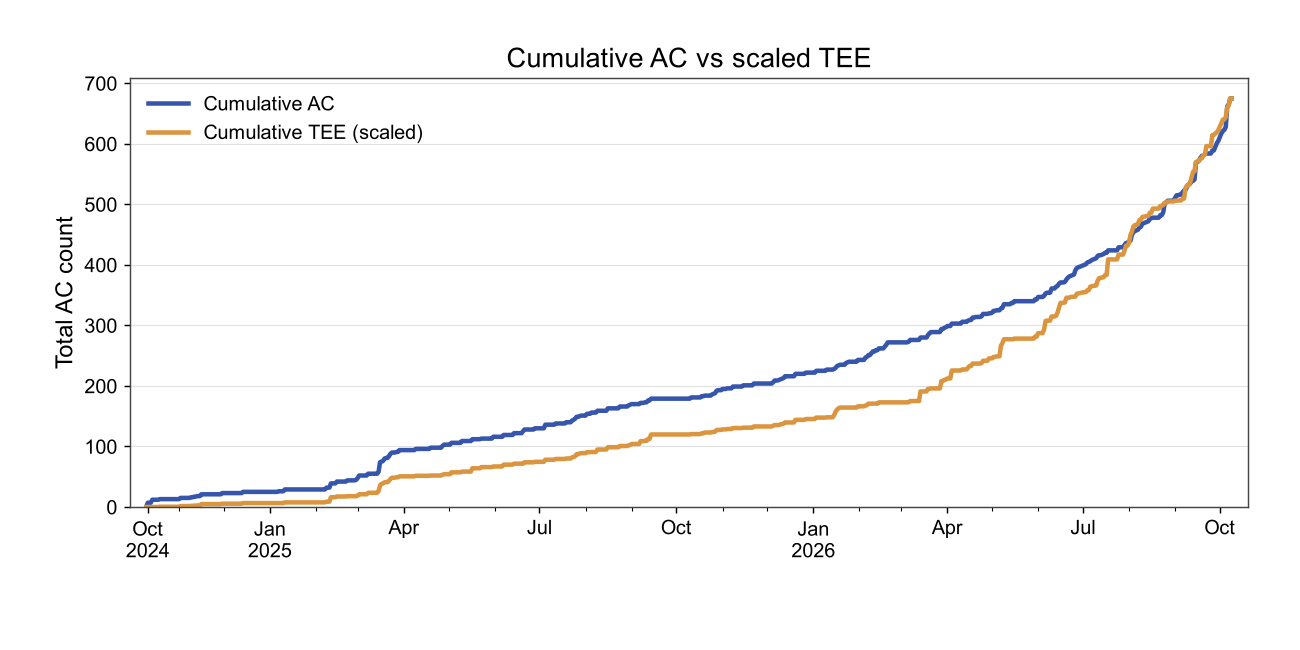

In [140]:
def _ac_tee_plot_comparison(result):
    # 共通関数で新しいFigureを作成。既存グラフのFigureやAxesは変更しない。
    compare_fig, compare_ax = figure('Cumulative AC vs scaled TEE')
    compare_dates = result['dates']
    compare_x = result['x']

    # 元の各日データをそのまま折れ線で表示（補間・平滑化・塗りつぶしなし）
    compare_ax.plot(compare_x, result['cumulative_ac'], color='#3655AC',
                    linewidth=2.5, label='Cumulative AC', zorder=3)
    compare_ax.plot(compare_x, result['scaled_tee'], color='#DB953F',
                    linewidth=2.5, label='Cumulative TEE (scaled)', zorder=3)

    # 既存Total Effortと同じ日付目盛り：期間に応じて日・月の間隔を切り替える
    if compare_dates:
        days = (compare_dates[-1] - compare_dates[0]).days
        if days <= 31:
            major_months, minor_months, day_step = 0, 0, 3
        elif days <= 92:
            major_months, minor_months, day_step = 0, 0, 7
        elif days <= 183:
            major_months, minor_months, day_step = 0, 0, 14
        elif days <= 366:
            major_months, minor_months, day_step = 1, 0, 0
        elif days <= 1096:
            major_months, minor_months, day_step = 3, 1, 0
        elif days <= 2192:
            major_months, minor_months, day_step = 6, 3, 0
        else:
            major_months, minor_months, day_step = 12, 3, 0

        if day_step:
            major = [i for i, day in enumerate(compare_dates)
                     if (day - compare_dates[0]).days % day_step == 0]
            minor = [i for i, day in enumerate(compare_dates)
                     if (day - compare_dates[0]).days % max(1, day_step // 2) == 0]
        else:
            major = [i for i, day in enumerate(compare_dates)
                     if day.day == 1 and (day.month - 1) % major_months == 0]
            minor = [i for i, day in enumerate(compare_dates)
                     if day.day == 1 and (day.month - 1) % (minor_months or major_months) == 0]
            major = sorted(set([0] + major))

        min_gap = max(1, int(len(compare_dates) * 0.045))
        major = [i for i in major if i == 0 or i >= min_gap]
        labels, previous_year = [], None
        for i in major:
            day = compare_dates[i]
            label = f'{day.strftime("%b")} {day.day}' if day_step else day.strftime('%b')
            labels.append(f'{label}\n{day.year}' if day.year != previous_year else label)
            previous_year = day.year

        compare_ax.xaxis.set_major_locator(_ac_tee_FixedLocator(major))
        compare_ax.set_xticklabels(labels)
        compare_ax.xaxis.set_minor_locator(_ac_tee_FixedLocator([i for i in minor if i not in major]))

    # 外枠・フォント・縦軸目盛り・横グリッドは既存Total Effortと同じ設定
    padding = len(compare_dates) * 0.015
    compare_ax.set_xlim(-1 - max(0.4, padding), len(compare_dates) - 1 + max(0.6, padding))
    compare_ax.set_ylim(bottom=0)
    compare_ax.set_ylabel('Total AC count', fontsize=13)
    compare_ax.title.set_fontsize(15)
    max_ac = max(result['cumulative_ac'], default=0)
    step = 50 if max_ac <= 300 else 100 if max_ac <= 1000 else 200 if max_ac <= 2000 else 500
    compare_ax.yaxis.set_major_locator(_ac_tee_MultipleLocator(step))
    compare_ax.tick_params(axis='both', colors='black', labelsize=11)
    compare_ax.set_axisbelow(True)
    compare_ax.yaxis.grid(True, color='#D5D5D5', linewidth=0.6, alpha=0.7)
    compare_ax.xaxis.grid(False, which='both')
    for spine in compare_ax.spines.values():
        spine.set_visible(True)
        spine.set_color('#454545')
        spine.set_linewidth(0.8)
        spine.set_zorder(10)
    compare_ax.legend(loc='upper left', frameon=False, fontsize=11)

    if result['zero_reason']:
        # カーブは0として表示し、計算できない理由は直前のセルに表示
        compare_ax.text(0.98, 0.04, 'TEE unavailable / zero', transform=compare_ax.transAxes,
                        ha='right', va='bottom', fontsize=10, color='#DB953F')
    return compare_fig


_ac_tee_compare_fig = _ac_tee_plot_comparison(_ac_tee_compare_result)
_ac_tee_display(_ac_tee_Image(data=png(_ac_tee_compare_fig).getvalue()))
